Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [1]:
import torch
import torch.nn.functional as F
from torch.nn import LayerNorm
from torch_geometric.nn import GATConv
from torch_geometric.data import Data
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split


The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [3]:
#Excel File Import
csv_file = 'Silicon_Dataset.csv'
df = pd.read_csv(csv_file)
df = df.apply(pd.to_numeric)

print(df.head())

    Lg  Lch    Tox          Nsub         PeakV  Vds       Vgs            Id
0  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -1.000000  3.220000e-16
1  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.974747  3.220000e-16
2  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.949495  3.210000e-16
3  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.924242  3.230000e-16
4  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.898990  3.230000e-16


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [4]:

# Assuming 'df' is your DataFrame and 'Id' is the target column
input_columns = ['Lg', 'Lch', 'Tox', 'Nsub', 'PeakV', 'Vds', 'Vgs']
output_column = 'Id'

# Prepare the data
X = df[input_columns]
Y = df[output_column]


This section of code mainly used do feature selection and show the importance of each different feature's relationship and importance between the factors.

In [5]:
# # Splitting the data into train and test sets
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# # Train a Random Forest Regressor model
# rf_model = RandomForestRegressor(random_state=42)
# rf_model.fit(X_train, Y_train)

# # Compute the baseline Mean Squared Error
# Y_pred = rf_model.predict(X_test)
# baseline_mse = mean_squared_error(Y_test, Y_pred)
# print(f"Baseline Mean Squared Error: {baseline_mse:.4f}")

# # Get feature importances
# feature_importances = rf_model.feature_importances_

# # Display feature importance
# feature_names = X_test.columns.tolist()
# importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
# importance_df = importance_df.sort_values(by='Importance', ascending=False)

# print(importance_df)

# # Plot feature importance
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'])
# plt.xlabel('Importance')
# plt.ylabel('Feature')
# plt.title('Feature Importance')
# plt.gca().invert_yaxis()
# plt.show()

This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [6]:

# Data Sampling: Pick the first 10000 samples
sample_num = 1000
X = X[:sample_num]
Y = Y[:sample_num]
 
# Divide the data into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Convert the data to PyTorch tensors
X_train = torch.tensor(X_train.values, dtype=torch.float)
y_train = torch.tensor(y_train.values, dtype=torch.float)
X_test = torch.tensor(X_test.values, dtype=torch.float)
y_test = torch.tensor(y_test.values, dtype=torch.float)




This part of the code is responsible for constructing specific datasets—both for training and testing the MLP (Multilayer Perceptron) model.
Constructs the training dataset and forms the testing dataset (test_dataset) by packing the remaining input-output pairs not included in the training set.

In [7]:
# Create a graph data object (example with fully connected graph)
train_edge_index = torch.combinations(torch.arange(X_train.size(0)), r=2).t().contiguous()
test_edge_index = torch.combinations(torch.arange(X_test.size(0)), r=2).t().contiguous()
data = Data(x=X_train, edge_index=train_edge_index, y=y_train)


# Using GCN model (CNN)
## GatGCN Framework

In [ ]:
# Define the RelGAT model
class RelGAT(torch.nn.Module):
    def __init__(self, in_channels, num_classes):
        super(RelGAT, self).__init__()

        # Define the hidden layers according to the specifications
        self.layers = torch.nn.ModuleList([
            GATConv(in_channels, 64, heads=2),  # 3 layers with 64 units
            GATConv(64 * 2, 64, heads=2),
            GATConv(64 * 2, 64, heads=2),

            GATConv(64 * 2, 128, heads=2),  # 6 layers with 128 units
            GATConv(128 * 2, 128, heads=2),
            GATConv(128 * 2, 128, heads=2),
            GATConv(128 * 2, 128, heads=2),
            GATConv(128 * 2, 128, heads=2),
            GATConv(128 * 2, 128, heads=2),

            GATConv(128 * 2, 256, heads=2),  # 3 layers with 256 units
            GATConv(256 * 2, 256, heads=2),
            GATConv(256 * 2, 256, heads=2),
        ])

        # MLP Layer (1(1))
        self.mlp = torch.nn.Linear(256 * 2, num_classes)

        # Layer Normalization
        self.norm_layers = torch.nn.ModuleList([LayerNorm(out_channels) for out_channels in 
                                                [64 * 2] * 3 + [128 * 2] * 6 + [256 * 2] * 3])

    def forward(self, x, edge_index):
        for i, layer in enumerate(self.layers):
            x = layer(x, edge_index)
            x = self.norm_layers[i](x)  # Apply LayerNorm
            x = F.relu(x)  # Apply activation function
        
        # Pass through final MLP layer
        x = self.mlp(x)
        return x

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Initialize model
model = RelGAT(in_channels=X_train.size(1), num_classes=1).to(device)  # Adjust num_classes as needed

# Move data to device
data = data.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # Learning rate adjustment
criterion = torch.nn.MSELoss()

# Training parameters
epochs = 50  
val_mse_list = []  # Store validation loss

# Training loop
model.train()
for epoch in tqdm(range(epochs), desc="Training"):
    optimizer.zero_grad()
    
    # Forward pass
    out = model(data.x, data.edge_index)
    
    # Compute loss
    loss = criterion(out.squeeze(), data.y)
    loss.backward()
    optimizer.step()
    
    # Validation
    model.eval()
    with torch.no_grad():
        test_data = Data(x=X_test, edge_index=test_edge_index, y=y_test).to(device)
        pred = model(test_data.x, test_data.edge_index).squeeze()
        val_mse = criterion(pred, test_data.y).item()
        val_mse_list.append(val_mse)
    
    model.train()  # Back to training mode
    
    print(f'Epoch {epoch+1}, Loss: {loss.item()}, Validation MSE: {val_mse}')


Training:   2%|▏         | 1/50 [00:12<10:01, 12.27s/it]

Epoch 1, Loss: nan, Validation MSE: nan


Training:   4%|▍         | 2/50 [00:21<08:15, 10.33s/it]

Epoch 2, Loss: nan, Validation MSE: nan


Training:   6%|▌         | 3/50 [00:29<07:18,  9.32s/it]

Epoch 3, Loss: nan, Validation MSE: nan


Training:   8%|▊         | 4/50 [00:37<06:46,  8.84s/it]

Epoch 4, Loss: nan, Validation MSE: nan


### Visualization of training process

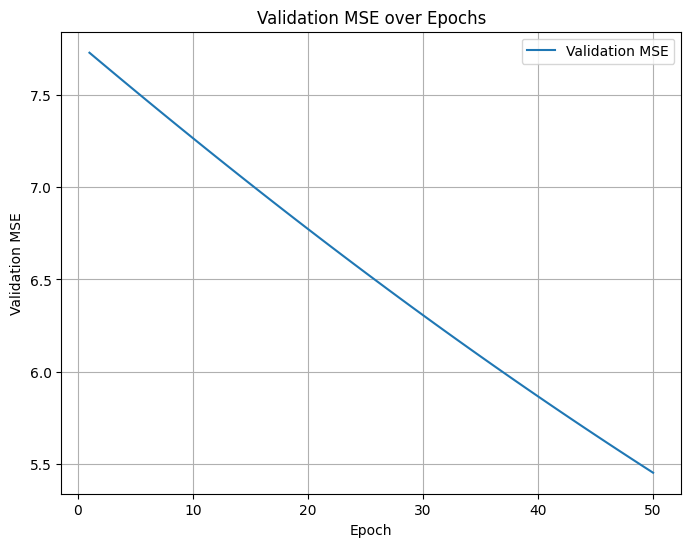

In [ ]:
# Plot the change of val_mse over epochs
plt.figure(figsize=(8, 6))
plt.plot(range(1, epochs + 1), val_mse_list, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Validation MSE over Epochs')
plt.legend()
plt.grid(True)
plt.show()